In [1]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
import random

/home/shoaib/Code/Shoaib/Lab/Agentic-AI/1_LangGraph/.venv/lib64/python3.14/site-packages/langchain_core/_api/deprecation.py:26: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1.fields import FieldInfo as FieldInfoV1


In [2]:
class AgentState(TypedDict):
    name: str
    nums: list[int]
    counter: int

In [3]:
def greet(state: AgentState) -> AgentState:
    """this function greets the user by name"""
    
    state['name'] = f"Hello, {state['name']}!"
    state['counter'] = 0
    return state

def random_num(state: AgentState) -> AgentState:
    """this function generates a random number and appends it to the nums list"""
    
    state['nums'].append(random.randint(0, 10))
    state['counter'] += 1
    return state

def decide_loop(state: AgentState) -> bool:
    """this function decides whether to continue the loop or not based on the counter value"""

    if state['counter'] < 5:
        return 'loop'
    else:
        return 'exit'

In [4]:
graph = StateGraph(AgentState)

graph.add_node('greet', greet)
graph.add_node('random', random_num)

graph.add_edge(START, 'greet')
graph.add_edge('greet', 'random')

graph.add_conditional_edges(
    'random',
    decide_loop,
    {
        'loop': 'random',
        'exit': END
    }
)

app = graph.compile()

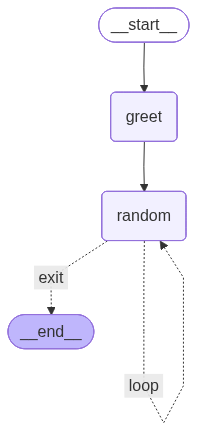

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
initial_state1 = AgentState(
    name='Alice',
    nums=[],
    counter=0
)

print(app.invoke(initial_state1))

{'name': 'Hello, Alice!', 'nums': [4, 10, 2, 3, 3], 'counter': 5}
